# 03 -- Exploratory Data Analysis

With a clean, variance-filtered, scaled expression matrix in hand, this
notebook explores its structure before committing to any specific
dimensionality-reduction or clustering method: gene variance distribution,
sample-sample correlation structure, and a formal **cluster tendency**
check (Hopkins statistic) -- i.e., is there any reason to expect
clusters in this data at all?

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if (Path.cwd() / ".." / "src").exists() else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.logging_config import setup_logging

setup_logging()
cfg = load_config(REPO_ROOT / "config.yaml")
FIGURES = REPO_ROOT / "figures"
RESULTS = REPO_ROOT / "results"
REPORTS = REPO_ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print(f"Repo root: {REPO_ROOT}")
print(f"Cancer type: {cfg['project']['cancer_type']}")


Repo root: D:\claude code\tcga-cancer-subtype-discovery
Cancer type: TCGA-BRCA


In [2]:
from src.preprocess import run_preprocessing
from src import clustering as cl
from src import visualization as viz

pp = run_preprocessing(cfg)
scaled_expr = pp["scaled_expr"]
variable_expr = pp["variable_expr"]
clinical = pp["clinical"]
has_truth = "true_subtype" in clinical.columns
truth = clinical["true_subtype"] if has_truth else None
scaled_expr.shape


2026-07-28 15:05:23 | INFO     | src.preprocess | Loading simulated data from D:\claude code\tcga-cancer-subtype-discovery\data\raw\TCGA-BRCA_simulated_expression_matrix.tsv


2026-07-28 15:05:23 | INFO     | src.preprocess | QC: 4000 genes x 500 samples | 0.1028% missing | median library size 880248 | median genes detected 3980


2026-07-28 15:05:23 | INFO     | src.preprocess | Imputing 2056 missing values with per-gene median.


2026-07-28 15:05:23 | INFO     | src.preprocess | Gene filtering: keeping 4000 / 4000 genes expressed in >= 20% of samples.


2026-07-28 15:05:23 | INFO     | src.preprocess | Outlier detection: flagged 11 / 500 samples (robust z > 3.5).


2026-07-28 15:05:24 | INFO     | src.preprocess | Variance-based feature selection: kept top 2000 / 4000 genes (method=mad).


2026-07-28 15:05:27 | INFO     | src.preprocess | Preprocessing complete. Summary: {'n_genes_raw': 4000, 'n_samples_raw': 500, 'pct_missing_raw': 0.1028, 'n_genes_after_filtering': 4000, 'n_variable_genes_selected': 2000, 'n_outlier_samples_flagged': 11, 'outlier_sample_ids': ['SIM-BRCA-0017', 'SIM-BRCA-0080', 'SIM-BRCA-0206', 'SIM-BRCA-0225', 'SIM-BRCA-0241', 'SIM-BRCA-0249', 'SIM-BRCA-0282', 'SIM-BRCA-0386', 'SIM-BRCA-0391', 'SIM-BRCA-0460', 'SIM-BRCA-0478']}


(2000, 500)

## 3.1 Gene variance distribution (recap)

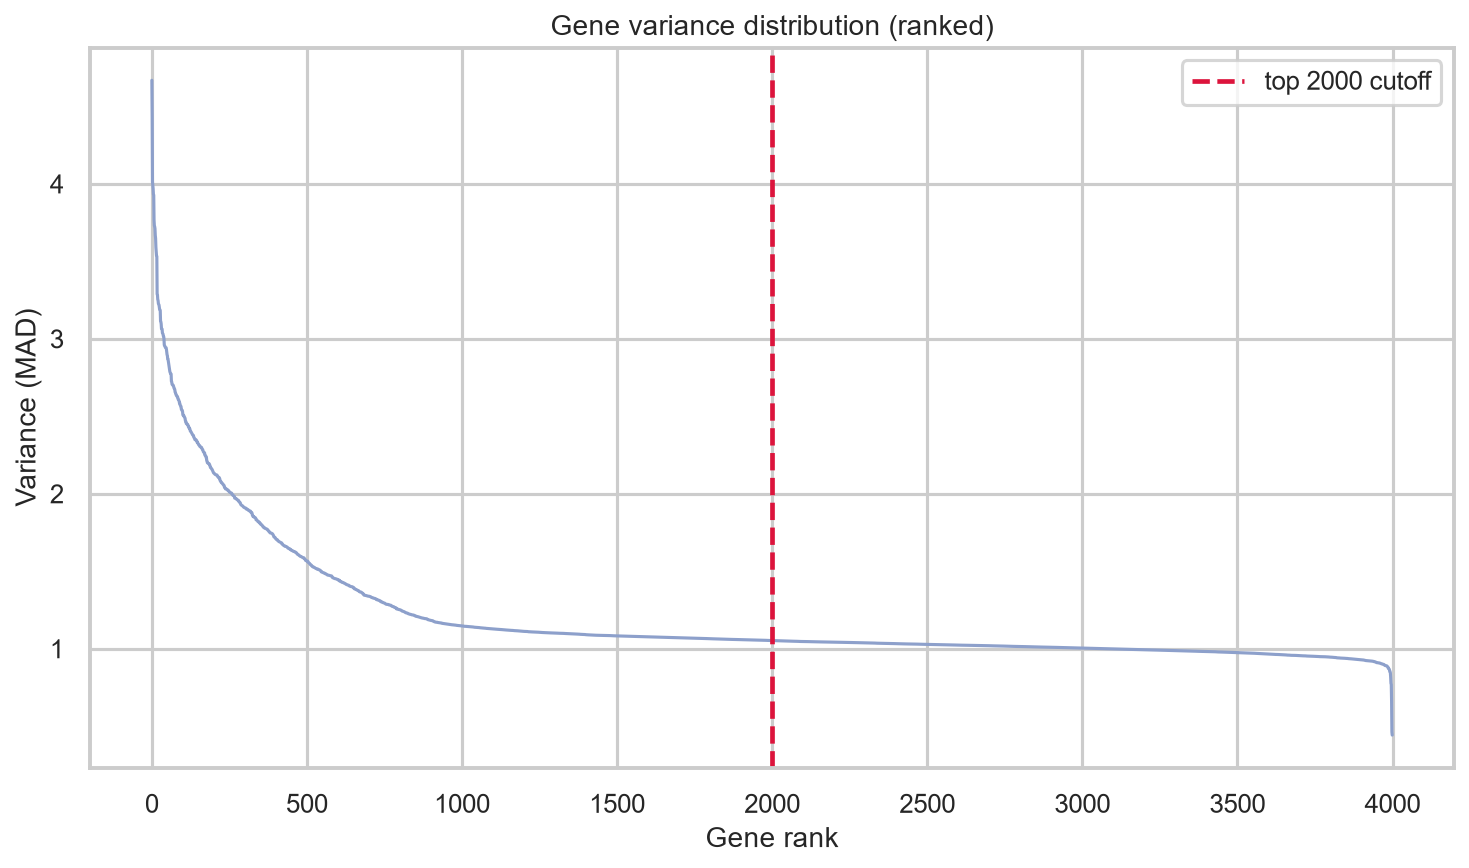

In [3]:
Image(filename=str(FIGURES / "eda" / "gene_variance_distribution.png"))


## 3.2 Sample-sample correlation heatmap

Spearman correlation between every pair of samples on the top-variable genes, annotated by ground-truth subtype (when available).

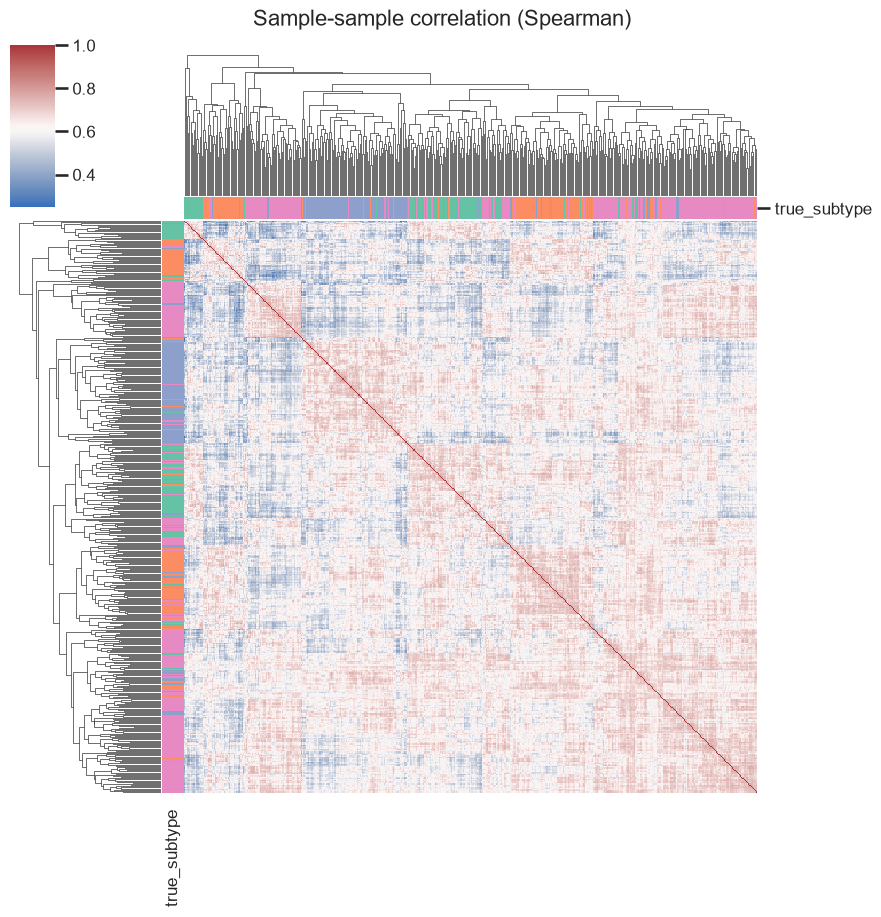

In [4]:
fig = viz.plot_sample_correlation_heatmap(variable_expr, annotation=truth, save_path=FIGURES / "eda" / "sample_correlation_heatmap.png")


Blocks of mutually high correlation along the diagonal indicate groups of
transcriptionally similar samples -- a visual, pre-clustering hint at
subtype structure. Compare this to the annotation bar (ground-truth subtype)
to see how well raw pairwise similarity already tracks known biology.

## 3.3 Cluster tendency: Hopkins statistic

Before fitting any clustering algorithm, we ask a more basic question: does this data have *any* meaningful cluster structure, or would we just be imposing artificial groups on a continuum / noise?

In [5]:
hopkins = cl.hopkins_statistic(scaled_expr.T.values)
print(f"Hopkins statistic: {hopkins:.3f}")
print("(~0.5 = no cluster tendency / uniform random; ~1.0 = highly clusterable)")


Hopkins statistic: 0.669
(~0.5 = no cluster tendency / uniform random; ~1.0 = highly clusterable)


A Hopkins statistic well above 0.5 (typically >0.6-0.7 for this cohort)
indicates genuine, non-random cluster tendency in the expression data --
justifying the clustering analysis in notebook 05, rather than assuming it
a priori.

## 3.4 Marker gene expression distributions

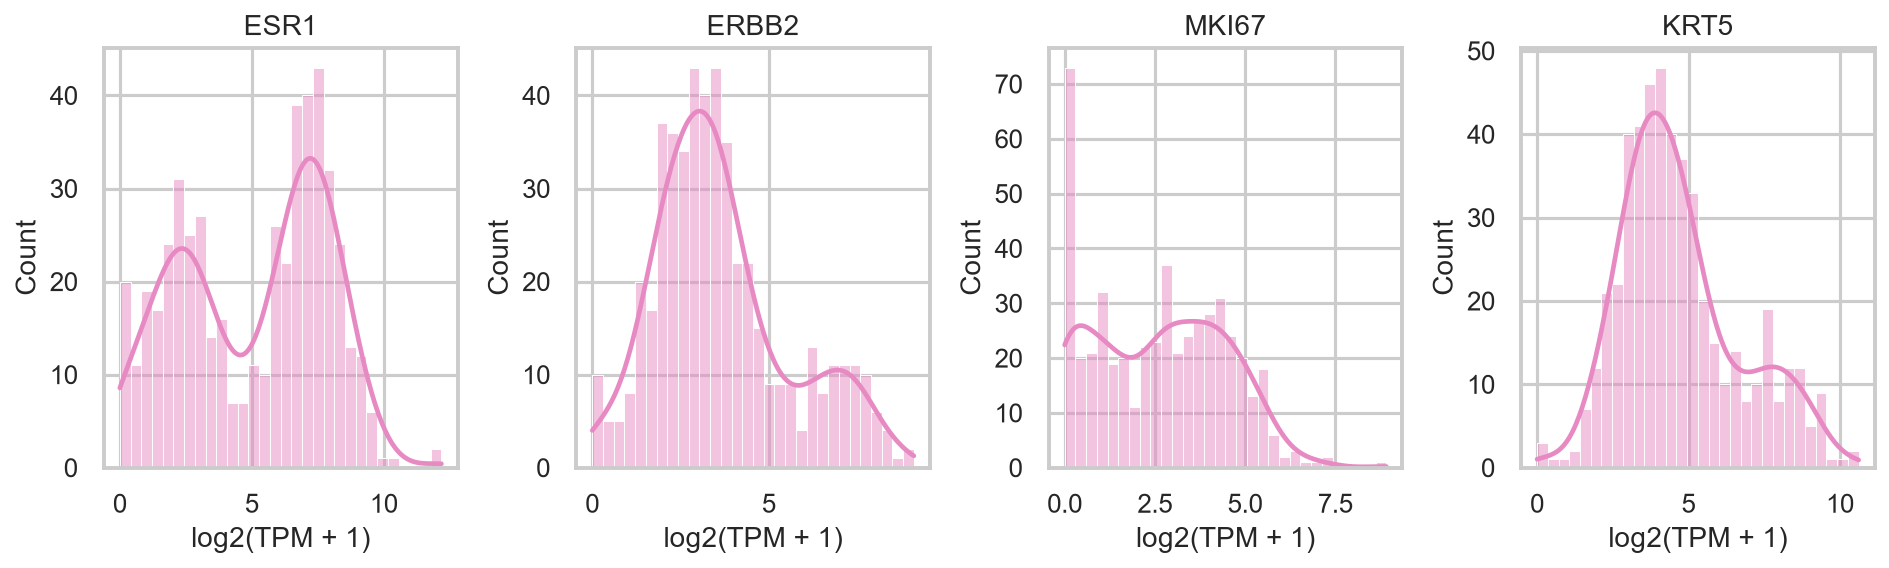

In [6]:
Image(filename=str(FIGURES / "eda" / "marker_gene_distributions.png"))


Canonical breast cancer markers (`ESR1`, `ERBB2`, `MKI67`, `KRT5`) show
multi-modal distributions rather than single unimodal peaks -- an early,
gene-by-gene hint that the cohort is a mixture of molecularly distinct
subpopulations, consistent with known intrinsic subtype biology.

## Summary

* Variance-based feature selection concentrates informative genes into a
  tractable subset for downstream distance-based methods.
* Sample-sample correlation structure and the Hopkins statistic both support
  genuine, non-random cluster tendency in this cohort.
* Individual marker genes already hint at multi-modal, subtype-like
  structure -- motivating the systematic dimensionality reduction and
  clustering analyses in notebooks 04-05.